# Week 9: Gradient Boosting
**Rupal Paliwal, Mod C, Semester 1**

**Datasets:** all three project datasets. **Part 1** uses the Movies Box Office data (4,803 films, 2000 to 2024). **Part 2** adds MovieLens 20M and the 4 Services Streaming catalogs (2,407 films from 2000 to 2015), plus the MovieLens tag genome.

**Question:** Can gradient boosting beat the Week 6 random forest (test R² 0.684 for revenue, 80.1% accuracy for hits)? And how do the learning rate, the number of trees, tree depth, and regularization change the results?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, accuracy_score, mean_squared_error

# Part 1: Box Office Data

## 1. Load and prepare the data

Same preparation as Weeks 2 and 4: rating converted from text like `'8.217/10'`, vote count logged, genres as 0/1 columns, the top 10 languages as 0/1 columns (English is the reference), and rows with missing or zero ratings dropped. The money columns other than the target are left out because worldwide gross is domestic plus foreign, so they would leak the answer.

Trees don't need feature scaling, so the features are used as they are.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi hot) and top 10 languages (English is the reference)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
y = np.log(data['$Worldwide'])                                   # revenue target (log scale)
threshold = df['$Worldwide'].median()
y_hit = (data['$Worldwide'] > threshold).astype(int)             # hit = above the median of all 5,000 films

# Same splits as earlier weeks, so results are comparable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_hit, test_size=0.2, random_state=42, stratify=y_hit)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (3842, 32) | Test: (961, 32)


## 2. Gradient boosting by hand

Gradient boosting builds trees one after another. Each new tree tries to predict what the model so far got wrong.

1. Start by predicting the average log revenue for every film.
2. Work out the **residuals** (actual minus predicted).
3. Fit a **stump** (a tree with one split) to the residuals.
4. Add the stump's predictions times the **learning rate** (0.5 here) to the running prediction.
5. Repeat.

I do three rounds by hand, then check that scikit learn's `GradientBoostingRegressor` gives the same answer.

In [3]:
learning_rate = 0.5
pred = np.full(len(y_train), y_train.mean())      # step 1: everyone gets the average
print('Start: predict the average,', round(y_train.mean(), 3), '| train RMSE', round(np.sqrt(mean_squared_error(y_train, pred)), 4))

for r in range(1, 4):
    residual = y_train - pred                                       # step 2
    stump = DecisionTreeRegressor(max_depth=1).fit(X_train, residual)   # step 3
    pred = pred + learning_rate * stump.predict(X_train)            # step 4
    feat = X.columns[stump.tree_.feature[0]]
    cut = stump.tree_.threshold[0]
    left, right = stump.tree_.value[1:, 0, 0]
    print(f'Round {r}: split on {feat} at {cut:.2f} (about {np.expm1(cut):,.0f} votes) | '
          f'residual guess {left:+.2f} below, {right:+.2f} above | train RMSE {np.sqrt(mean_squared_error(y_train, pred)):.4f}')

Start: predict the average, 17.878 | train RMSE 1.1875
Round 1: split on log_votes at 7.56 (about 1,910 votes) | residual guess -0.57 below, +0.98 above | train RMSE 0.9960
Round 2: split on log_votes at 8.42 (about 4,538 votes) | residual guess -0.22 below, +1.04 above | train RMSE 0.9068
Round 3: split on log_votes at 6.53 (about 684 votes) | residual guess -0.38 below, +0.26 above | train RMSE 0.8642


In [4]:
gb3 = GradientBoostingRegressor(n_estimators=3, learning_rate=0.5, max_depth=1, random_state=42).fit(X_train, y_train)
print('scikit learn, 3 stumps, learning rate 0.5: train RMSE', round(np.sqrt(mean_squared_error(y_train, gb3.predict(X_train))), 4))

scikit learn, 3 stumps, learning rate 0.5: train RMSE 0.8642


The numbers match, so the library is doing exactly the steps above. Every round splits on vote count, at a different cutoff each time. Each stump is a **weak learner**: on its own it explains little, but together they keep chipping away at the error.

## 3. Learning rate and number of trees

A smaller learning rate takes smaller steps, so it needs more trees to get to the same place. To choose the number of trees without touching the test set, I hold out 25% of the training films as a **validation** set and track validation R² after every tree.

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0)

curves, rows = {}, []
for lr in [1.0, 0.3, 0.1, 0.03]:
    start = time.time()
    m = GradientBoostingRegressor(n_estimators=1500, learning_rate=lr, max_depth=3, random_state=42).fit(X_fit, y_fit)
    curves[lr] = [r2_score(y_val, p) for p in m.staged_predict(X_val)]    # validation R2 after each tree
    rows.append({'learning_rate': lr,
                 'best_number_of_trees': int(np.argmax(curves[lr])) + 1,
                 'best_validation_R2': round(max(curves[lr]), 4),
                 'validation_R2_at_1500_trees': round(curves[lr][-1], 4),
                 'seconds': round(time.time() - start, 1)})
pd.DataFrame(rows)

,learning_rate,best_number_of_trees,best_validation_R2,validation_R2_at_1500_trees,seconds
0,1.00,12,0.6696,0.4631,5.7
1,0.30,110,0.6937,0.6139,5.8
2,0.10,280,0.6923,0.6675,5.7
3,0.03,839,0.6958,0.6931,5.9


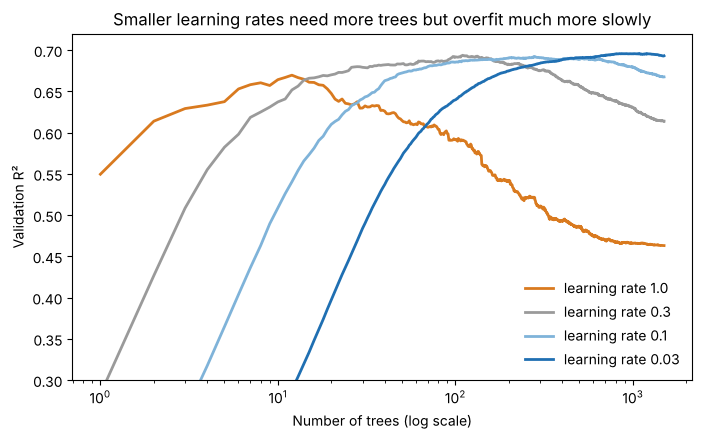

In [6]:
plt.figure(figsize=(8, 4.5))
colors = {1.0: '#d97a1f', 0.3: '#9a9a9a', 0.1: '#7fb3d9', 0.03: '#1f6fb2'}
for lr, c in curves.items():
    plt.plot(range(1, 1501), c, color=colors[lr], linewidth=2, label=f'learning rate {lr}')
plt.xscale('log')
plt.ylim(0.3, 0.72)
plt.xlabel('Number of trees (log scale)')
plt.ylabel('Validation R²')
plt.title('Smaller learning rates need more trees but overfit much more slowly')
plt.legend(frameon=False)
plt.show()

With a learning rate of 1.0 the model peaks after only about a dozen trees and then gets steadily worse, because every new tree overcorrects. Smaller learning rates climb slowly, peak later, and reach a higher best score (about 0.69 to 0.70 versus 0.67). They are also much more forgiving: at 0.03, adding hundreds of extra trees barely hurts. The cost is training time.

## 4. Tree depth

Each weak learner can be a stump (depth 1) or a deeper tree. Deeper trees can capture interactions between features (for example, votes matter differently for films in other languages), but they also overfit sooner.

In [7]:
rows = []
for d in [1, 2, 3, 5, 8]:
    m = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=d, random_state=42)
    cv = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2').mean()
    m.fit(X_train, y_train)
    rows.append({'max_depth': d, 'train_R2': round(r2_score(y_train, m.predict(X_train)), 4), 'CV_R2': round(cv, 4)})
depth_table = pd.DataFrame(rows)
depth_table

,max_depth,train_R2,CV_R2
0,1,0.6522,0.6323
1,2,0.7348,0.6842
2,3,0.7914,0.6896
3,5,0.8967,0.6752
4,8,0.9845,0.6488


Stumps underfit (training and CV R² both lowest). CV R² peaks at a depth of about 3. Deeper trees keep raising training R² toward 1 while CV R² falls, which is overfitting.

## 5. Regularization

The lesson lists three ways to regularize gradient boosting:
1. **Limit complexity.** scikit learn does this through the size of each tree (`max_depth`, or `max_leaf_nodes`). Libraries such as XGBoost also add a direct penalty per leaf.
2. **Minimum samples per leaf** (`min_samples_leaf`): no prediction can be based on a tiny group of films.
3. **Subsampling** (`subsample`): each tree is trained on a random share of the training films, which adds randomness like a random forest.

I tune all three together with 5 fold CV, using a learning rate of 0.05 and 400 trees. This takes a couple of minutes.

In [8]:
start = time.time()
search = GridSearchCV(
    GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, random_state=42),
    {'max_depth': [2, 3, 4], 'min_samples_leaf': [1, 10, 30], 'subsample': [0.5, 0.8, 1.0]},
    cv=kf, scoring='r2', n_jobs=-1).fit(X_train, y_train)
gb_best = search.best_estimator_
print('Best settings:', search.best_params_, f'({time.time() - start:.0f} seconds)')
print('Train R2:', round(r2_score(y_train, gb_best.predict(X_train)), 4))
print('CV R2:   ', round(search.best_score_, 4))
print('Test R2: ', round(r2_score(y_test, gb_best.predict(X_test)), 4))

Best settings: {'max_depth': 4, 'min_samples_leaf': 10, 'subsample': 0.8} (87 seconds)
Train R2: 0.8099
CV R2:    0.7071
Test R2:  0.7011


In [9]:
res = pd.DataFrame(search.cv_results_)
print('Best CV R2 for each subsample value:')
print(res.groupby('param_subsample')['mean_test_score'].max().round(4).to_string())
print()
print('Best CV R2 for each min_samples_leaf value:')
print(res.groupby('param_min_samples_leaf')['mean_test_score'].max().round(4).to_string())

Best CV R2 for each subsample value:
param_subsample
0.5    0.7047
0.8    0.7071
1.0    0.7028

Best CV R2 for each min_samples_leaf value:
param_min_samples_leaf
1     0.6983
10    0.7071
30    0.7046


Both kinds of regularization help a little. Training each tree on 80% of the films beats using all of them, and requiring at least 10 films per leaf beats allowing leaves with a single film.

**Early stopping** is one more form of regularization: keep adding trees until a held out slice of the training data stops improving.

In [10]:
es = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.05, validation_fraction=0.15, n_iter_no_change=50,
                               random_state=42, **{k: v for k, v in search.best_params_.items()}).fit(X_train, y_train)
print('Early stopping chose', es.n_estimators_, 'trees out of a possible 3,000')
print('Test R2:', round(r2_score(y_test, es.predict(X_test)), 4))

Early stopping chose 270 trees out of a possible 3,000
Test R2: 0.7007


## 6. How gradient boosting compares (revenue, same test films)

In [11]:
pd.DataFrame({
    'model': ['Linear regression (Week 2)', 'Linear + squared terms (Week 1)', 'Random forest (Week 6)', 'Gradient boosting, tuned'],
    'test_R2': [0.5256, 0.6172, 0.6839, round(r2_score(y_test, gb_best.predict(X_test)), 4)]})

,model,test_R2
0,Linear regression (Week 2),0.5256
1,Linear + squared terms (Week 1),0.6172
2,Random forest (Week 6),0.6839
3,"Gradient boosting, tuned",0.7011


In [12]:
perm = permutation_importance(gb_best, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(8).round(3).rename('R2_drop_when_shuffled')

log_votes          1.377
year               0.181
lang_zh            0.060
rating             0.049
genre_Family       0.024
genre_Adventure    0.012
lang_fr            0.005
genre_Action       0.005
Name: R2_drop_when_shuffled, dtype: float64

## 7. Hit classification

In [13]:
start = time.time()
clf_search = GridSearchCV(
    GradientBoostingClassifier(n_estimators=300, random_state=42),
    {'learning_rate': [0.03, 0.1], 'max_depth': [2, 3, 4], 'subsample': [0.8, 1.0]},
    cv=skf, n_jobs=-1).fit(Xc_train, yc_train)
print('Best settings:', clf_search.best_params_, f'({time.time() - start:.0f} seconds)')
print('CV accuracy:  ', round(clf_search.best_score_, 4))
print('Test accuracy:', round(accuracy_score(yc_test, clf_search.predict(Xc_test)), 4))

Best settings: {'learning_rate': 0.03, 'max_depth': 4, 'subsample': 0.8} (36 seconds)
CV accuracy:   0.8035
Test accuracy: 0.7877


In [14]:
pd.DataFrame({
    'model': ['Logistic regression (Week 4)', 'Linear SVM (Week 5)', 'Random forest (Week 6)', 'Gradient boosting, tuned'],
    'test_accuracy': [0.7825, 0.7836, 0.8012, round(accuracy_score(yc_test, clf_search.predict(Xc_test)), 4)]})

,model,test_accuracy
0,Logistic regression (Week 4),0.7825
1,Linear SVM (Week 5),0.7836
2,Random forest (Week 6),0.8012
3,"Gradient boosting, tuned",0.7877


# Part 2: All Three Project Datasets

Same approach as Part 2 of Weeks 1 to 6: the 2,407 films from 2000 to 2015 that matched MovieLens, fit once with the 32 box office features and once with 39 features from all three datasets (adding MovieLens rating count, average rating, and tag count, and a flag for each streaming service). `combined_films.csv` and `genome_features.csv` come from `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb`. The gradient boosting settings are the ones tuned in Part 1.

In [15]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = np.log(sub['$Worldwide'])                     # log worldwide gross
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])
y3_hit = (sub['$Worldwide'] > threshold).astype(int)

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


In [16]:
best = dict(n_estimators=400, learning_rate=0.05, random_state=42, **search.best_params_)
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42)
trc3, tec3 = train_test_split(XA.index, test_size=0.2, random_state=42, stratify=y3_hit)
rows = []
for name, Z in [('Box office only', XA), ('All three datasets', XB)]:
    reg = GradientBoostingRegressor(**best).fit(Z.loc[tr3], y3[tr3])
    clf = GradientBoostingClassifier(**best).fit(Z.loc[trc3], y3_hit[trc3])
    rows.append({'features': name, 'n_features': Z.shape[1],
                 'test_R2 (revenue)': round(r2_score(y3[te3], reg.predict(Z.loc[te3])), 4),
                 'test_accuracy (hit)': round(accuracy_score(y3_hit[tec3], clf.predict(Z.loc[tec3])), 4)})
print('Week 6 random forest on the same films: R2 0.712 / 0.731, accuracy 80.3% / 80.9%')
pd.DataFrame(rows)

Week 6 random forest on the same films: R2 0.712 / 0.731, accuracy 80.3% / 80.9%


,features,n_features,test_R2 (revenue),test_accuracy (hit)
0,Box office only,32,0.7231,0.7946
1,All three datasets,39,0.7452,0.8216


## P2.2 Gradient boosting on the MovieLens tag genome

In Week 2, lasso did best with the 1,128 genome tags (test R² 0.812), and in Week 6 the random forest reached only 0.745 on the same films. Gradient boosting builds each tree on what the earlier trees missed, so once vote count is used up, later trees can focus on the few tags that still help. This cell takes a few minutes because every split looks at all 1,167 features.

In [17]:
# MovieLens tag genome: 1,128 relevance scores (0 to 1) per film, saved by the data prep notebook
genome = pd.read_csv('genome_features.csv', index_col=0)
has_genome = sub['ml_movieId'].astype(int).isin(genome.index)
gsub = sub[has_genome]
G = genome.loc[gsub['ml_movieId'].astype(int)].set_index(gsub.index)
print('Films with tag genome scores:', len(gsub), '| genome tags:', G.shape[1])

Films with tag genome scores: 2179 | genome tags: 1128


In [18]:
start = time.time()
XG = pd.concat([XB.loc[gsub.index], G], axis=1)
y_g = y3[gsub.index]
trg, teg = train_test_split(XG.index, test_size=0.2, random_state=42)
gb_no_genome = GradientBoostingRegressor(**best).fit(XB.loc[trg], y_g[trg])
gb_genome = GradientBoostingRegressor(**best).fit(XG.loc[trg], y_g[trg])
print(f'({time.time() - start:.0f} seconds)')
pd.DataFrame({
    'model (same films and split)': ['Random forest + genome (Week 6)', 'Lasso + genome (Week 2)',
                                     'Gradient boosting, no genome', 'Gradient boosting + genome'],
    'test_R2': [0.7452, 0.8122,
                round(r2_score(y_g[teg], gb_no_genome.predict(XB.loc[teg])), 4),
                round(r2_score(y_g[teg], gb_genome.predict(XG.loc[teg])), 4)]})

(172 seconds)


,model (same films and split),test_R2
0,Random forest + genome (Week 6),0.7452
1,Lasso + genome (Week 2),0.8122
2,"Gradient boosting, no genome",0.7504
3,Gradient boosting + genome,0.8221


In [19]:
perm_g = permutation_importance(gb_genome, XG.loc[teg], y_g[teg], n_repeats=3, random_state=42, n_jobs=-1)
imp_g = pd.Series(perm_g.importances_mean, index=XG.columns).sort_values(ascending=False)
print('Genome tags among the 15 most important features:', [c for c in imp_g.head(15).index if c.startswith('tag_')])
imp_g.head(15).round(4).rename('R2_drop_when_shuffled')

Genome tags among the 15 most important features: ['tag_low budget', 'tag_family', 'tag_adventure', 'tag_overrated', 'tag_dreamworks', 'tag_time loop', 'tag_prequel', 'tag_talking animals', 'tag_3d', 'tag_propaganda', 'tag_adolescence', 'tag_big budget']


log_votes              0.8156
ml_log_ratings         0.0242
year                   0.0171
tag_low budget         0.0126
tag_family             0.0050
tag_adventure          0.0046
tag_overrated          0.0043
tag_dreamworks         0.0042
tag_time loop          0.0030
tag_prequel            0.0030
tag_talking animals    0.0026
tag_3d                 0.0021
tag_propaganda         0.0019
tag_adolescence        0.0017
tag_big budget         0.0015
Name: R2_drop_when_shuffled, dtype: float64

# Conclusions

**Gradient boosting is the best revenue model so far.** Tuned (depth 4, at least 10 films per leaf, 80% subsample, learning rate 0.05, 400 trees), it reaches a test R² of **0.701** on all films, ahead of the Week 6 random forest (0.684), squared terms (0.617), and linear regression (0.526). Its CV R² (0.707) matches the test score, so it is not overfitting even though its training R² is 0.810.

**Learning rate and number of trees work as a pair.** At a learning rate of 1.0 the model peaked after 12 trees and then fell to a validation R² of 0.463 by 1,500 trees, because each tree overcorrected. At 0.03 it needed about 840 trees but reached the best score (0.696) and barely dropped after that. Early stopping found a good number of trees automatically (270 at a learning rate of 0.05) with the same test R² (0.701).

**Tree depth controls underfitting and overfitting.** Stumps underfit (CV R² 0.632). Depth 3 to 4 was best. Depth 8 overfit: training R² 0.985 but CV R² only 0.649.

**Regularization helped a little.** CV preferred training each tree on 80% of the films and at least 10 films per leaf over no regularization. The gains were small (about 0.004 to 0.009 in CV R²) because the learning rate and depth limit were already doing most of the work.

**For hit classification, boosting did not beat the random forest.** It scored 80.4% in CV but 78.8% on the test films, below the forest's 80.1%. The gap is within normal random variation for 961 test films, so the honest conclusion is that boosting and the forest are about equally good at the yes or no question, while boosting is clearly better at predicting how much a film earns.

**Part 2 (all three datasets).** On the 2000 to 2015 films, boosting again beat the Week 6 forest (R² 0.723 vs. 0.712 with box office features, 0.745 vs. 0.731 with all three datasets), and the MovieLens and streaming features raised its hit accuracy from 79.5% to 82.2%. With the 1,128 genome tags, boosting reached a test R² of **0.822**, the best result of the module, ahead of lasso (0.812) and far ahead of the random forest (0.745). The random forest's trees are independent, so each one mostly relearns vote count; boosting's later trees work only on what is left over, which lets them find the few useful tags. The tags it relies on ("low budget", "family", "adventure", "prequel", "3d", "big budget", "DreamWorks") mostly describe what kind of film it is and how it was made, the kind of information a studio has before release.

**What drives revenue has not changed:** vote count first, then year, then Chinese language, then rating, the same order as the Week 6 forest.

### Think About It

- **How is gradient boost similar to random forest?** Both combine many decision trees into one model, both handle curved relationships and interactions without feature scaling, both can add randomness by training trees on a subsample of the data, and both give feature importances.
- **How is gradient boost different from random forest?** A random forest grows deep trees *independently* on bootstrap samples and *averages* them, which mainly reduces variance (overfitting). Gradient boosting grows shallow trees *one after another*, each fitting the errors left by the trees before it, and *adds* them up with a learning rate, which mainly reduces bias (underfitting). Boosting is also more sensitive to its settings: with a learning rate of 1.0 it overfit within a dozen trees, while a forest gets no worse as trees are added.
- **Does a small learning rate generally lead to higher or lower accuracy? Why?** Higher, as long as there are enough trees. Each tree only corrects part of the remaining error, so no single tree can overcorrect, and many small steps smooth out noise. In my data, a learning rate of 0.03 reached the best validation R² (0.696 vs. 0.670 at 1.0). The costs are about 70 times as many trees (839 vs. 12) and longer training, and with too few trees a small learning rate underfits.